# Wine Quality Classification — Diagnostic Notebook

This notebook manually replicates the bot pipeline to diagnose why accuracy is stuck at ~37%.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset
df = pd.read_csv('wine_quality_classification.csv')
print('Shape:', df.shape)
df.head()

Shape: (1000, 5)


,fixed_acidity,residual_sugar,alcohol,density,quality_label
0,9.3,6.4,13.6,1.0005,high
1,11.2,2.0,14.0,0.9912,medium
2,11.6,0.9,8.2,0.9935,low
3,12.9,6.6,12.7,1.0002,low
4,13.9,13.8,10.4,0.9942,medium


## 1. Class Distribution — Is it imbalanced?

Class distribution:
quality_label
medium    355
high      343
low       302
Name: count, dtype: int64

Class proportions:
quality_label
medium    0.355
high      0.343
low       0.302
Name: proportion, dtype: float64


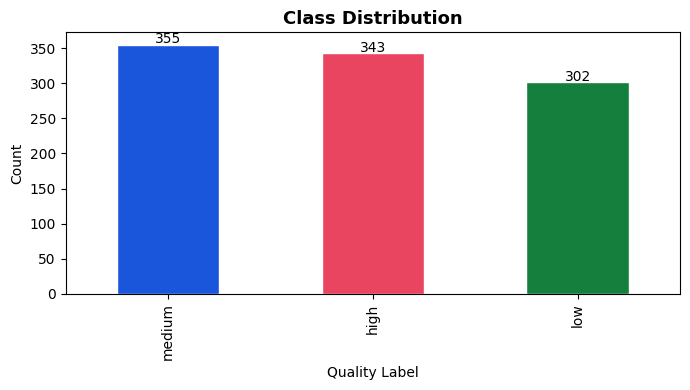

In [2]:
print('Class distribution:')
print(df['quality_label'].value_counts())
print('\nClass proportions:')
print(df['quality_label'].value_counts(normalize=True).round(3))

fig, ax = plt.subplots(figsize=(7, 4))
df['quality_label'].value_counts().plot(kind='bar', ax=ax, color=['#1a56db','#e94560','#15803d'], edgecolor='white')
ax.set_title('Class Distribution', fontsize=13, fontweight='bold')
ax.set_xlabel('Quality Label')
ax.set_ylabel('Count')
for p in ax.patches:
    ax.annotate(str(int(p.get_height())), (p.get_x() + p.get_width()/2, p.get_height()+2), ha='center')
plt.tight_layout()
plt.show()

## 2. Feature Correlation — Can features actually predict quality?

In [3]:
# Check if features have any discriminative power
le = LabelEncoder()
df['quality_numeric'] = le.fit_transform(df['quality_label'])
print('Label encoding:', dict(zip(le.classes_, le.transform(le.classes_))))

# Feature-target correlations
features = ['fixed_acidity', 'residual_sugar', 'alcohol', 'density']
corr_with_target = df[features + ['quality_numeric']].corr()['quality_numeric'].drop('quality_numeric')
print('\nCorrelation with quality_numeric:')
print(corr_with_target.sort_values(ascending=False))

Label encoding: {'high': 0, 'low': 1, 'medium': 2}

Correlation with quality_numeric:
residual_sugar    0.032096
density           0.006529
fixed_acidity    -0.035240
alcohol          -0.075168
Name: quality_numeric, dtype: float64


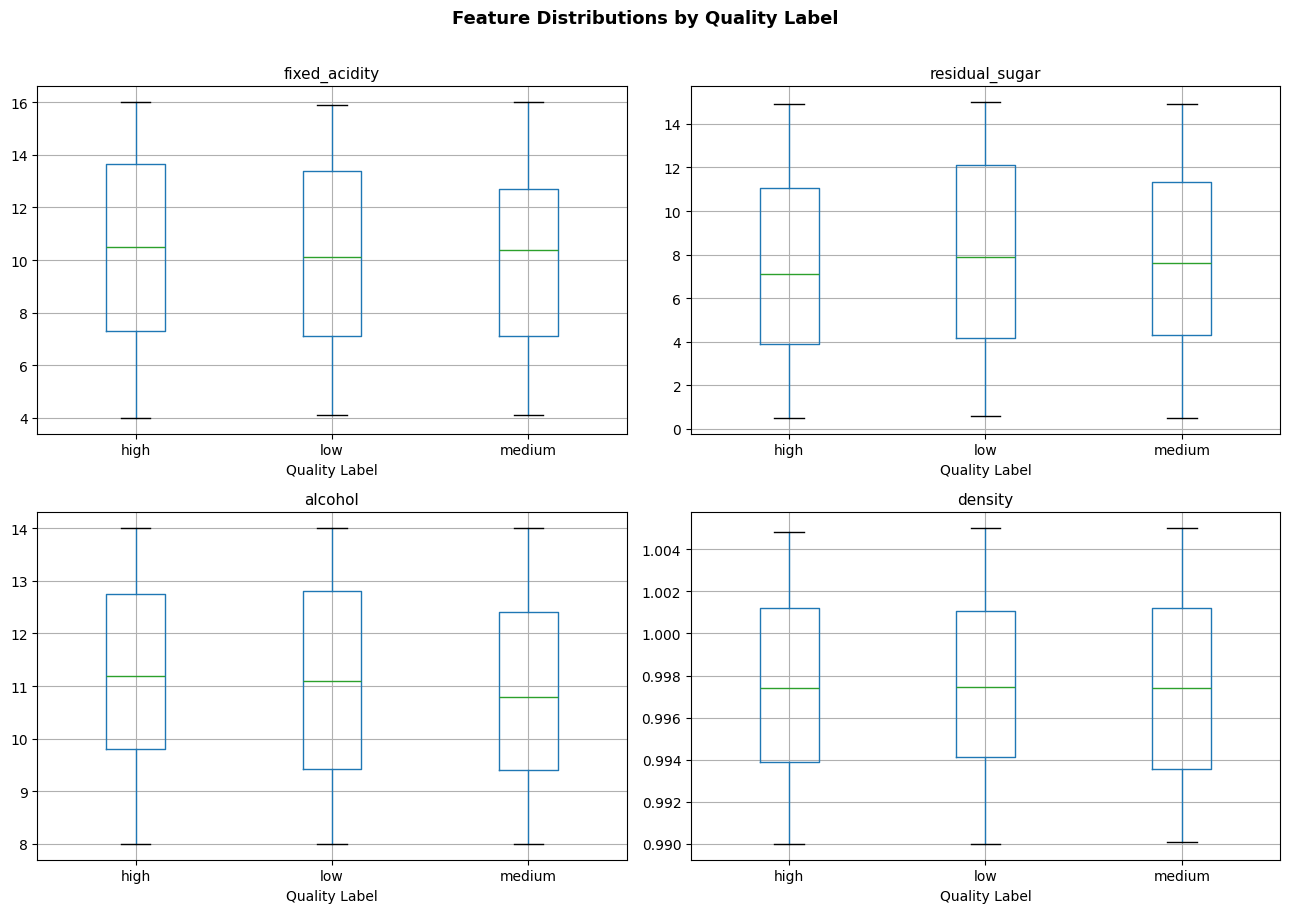

In [4]:
# Box plots — do feature distributions actually differ between classes?
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, feat in zip(axes.flat, features):
    df.boxplot(column=feat, by='quality_label', ax=ax)
    ax.set_title(feat, fontsize=11)
    ax.set_xlabel('Quality Label')
fig.suptitle('Feature Distributions by Quality Label', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 3. Manual Model Training — Replicate the bot pipeline exactly

In [5]:
X = df[features].copy()
y_raw = df['quality_label']

# Encode target using LabelEncoder (same as bot)
le = LabelEncoder()
y = le.fit_transform(y_raw)
print('Classes:', le.classes_, '→', le.transform(le.classes_))

# Scale (standard scaler, same as bot)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 80/20 split with stratify (same as bot)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')

Classes: ['high' 'low' 'medium'] → [0 1 2]
Train: (800, 4), Test: (200, 4)


In [6]:
# 5-fold CV on training set only (same as bot)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    'LogisticRegression (balanced)': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'LogisticRegression (unbalanced)': LogisticRegression(max_iter=1000, random_state=42),
    'RandomForest (balanced)': RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42),
    'RandomForest (unbalanced)': RandomForestClassifier(n_estimators=200, random_state=42),
    'GradientBoosting': GradientBoostingClassifier(n_estimators=200, random_state=42),
}

print(f'{"Model":<40} {"CV Mean":>10} {"CV Std":>10} {"Test Acc":>10}')
print('-' * 75)
for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    model.fit(X_train, y_train)
    test_acc = accuracy_score(y_test, model.predict(X_test))
    print(f'{name:<40} {cv_scores.mean():>10.4f} {cv_scores.std():>10.4f} {test_acc:>10.4f}')

Model                                       CV Mean     CV Std   Test Acc
---------------------------------------------------------------------------
LogisticRegression (balanced)                0.3475     0.0239     0.3100
LogisticRegression (unbalanced)              0.3725     0.0384     0.3750
RandomForest (balanced)                      0.3250     0.0172     0.3000
RandomForest (unbalanced)                    0.3187     0.0190     0.3400
GradientBoosting                             0.3212     0.0460     0.3500


## 4. Classification Report — Per-class breakdown of the best model

Classification Report (RandomForest balanced):
              precision    recall  f1-score   support

        high       0.34      0.33      0.34        69
         low       0.21      0.20      0.21        60
      medium       0.33      0.35      0.34        71

    accuracy                           0.30       200
   macro avg       0.29      0.30      0.29       200
weighted avg       0.30      0.30      0.30       200



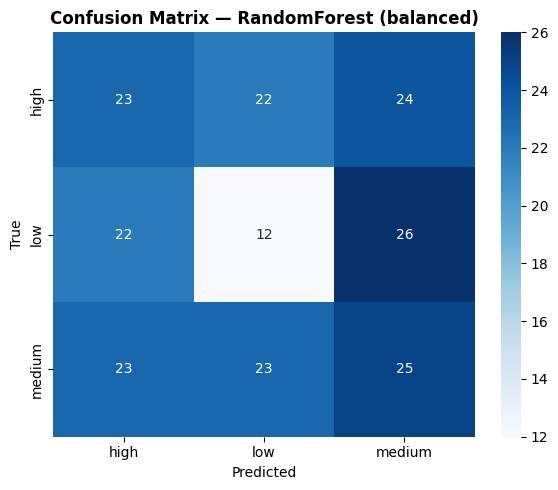

In [7]:
best_model = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print('Classification Report (RandomForest balanced):')
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=le.classes_, yticklabels=le.classes_)
ax.set_title('Confusion Matrix — RandomForest (balanced)', fontweight='bold')
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
plt.tight_layout()
plt.show()

## 5. Feature Importance — What is the model actually using?

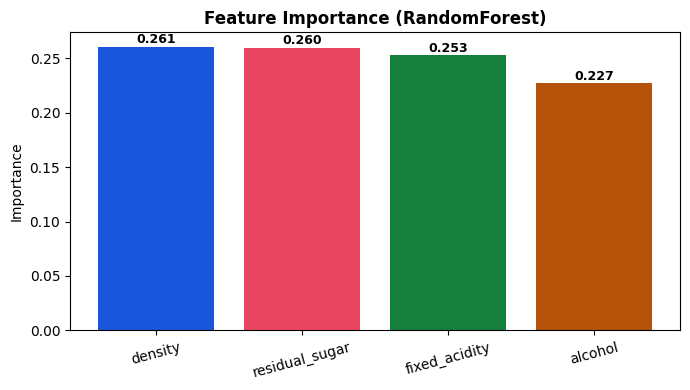

In [8]:
importances = best_model.feature_importances_
indices = np.argsort(importances)[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(len(features)), importances[indices], color=['#1a56db','#e94560','#15803d','#b45309'])
ax.set_xticks(range(len(features)))
ax.set_xticklabels([features[i] for i in indices], rotation=15)
ax.set_title('Feature Importance (RandomForest)', fontsize=12, fontweight='bold')
ax.set_ylabel('Importance')
for i, imp in enumerate(importances[indices]):
    ax.text(i, imp + 0.003, f'{imp:.3f}', ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Conclusion — Why is the accuracy low?

- If the class distribution is **roughly equal (33% each)**, then ~37% accuracy is only slightly above random chance (~33%), so the model is barely learning anything.
- If feature correlations with the target are **near 0**, the features are simply not predictive of quality_label.
- If the confusion matrix shows the model **can't distinguish low vs high**, the dataset likely doesn't have clear boundaries.

**Key question: Is this a synthetic or real dataset?** If the labels (low/medium/high) were randomly assigned or based on extremely weak rules, no model can reliably learn them regardless of algorithm choice.